# Cat and Dog Image Classification using MobileNetV2 and ONNX Export

This notebook trains a binary image classifier (Cats vs. Dogs) using transfer learning with MobileNetV2 in TensorFlow, evaluates it on a test set, and exports the final trained model into the **ONNX** format instead of `.keras`.

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, Sequential
from tensorflow.keras.utils import img_to_array, load_img
import matplotlib.pyplot as plt
import numpy as np
import os
from PIL import Image
import tf2onnx
import onnx

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Load Dataset

In [2]:
possible_paths = [
    './dataset',
    '../dataset',
    os.path.join(os.getcwd(), 'dataset')
]

data_dir = None
for path in possible_paths:
    if os.path.exists(path):
        data_dir = path
        break

if data_dir:
    print(f"✅ Dataset found at: {os.path.abspath(data_dir)}")
else:
    print("❌ Dataset not found! Make sure your 'dataset' folder contains 'cats' and 'dogs' subfolders.")

BATCH_SIZE = 32
IMG_SIZE = (160, 160)
MAX_IMAGES_PER_CLASS = 3000  # Adjust lower if you hit memory issues

✅ Dataset found at: d:\MTEC\Image-Processing\Cat and Dog Classification\dataset


In [3]:
print(f"Loading up to {MAX_IMAGES_PER_CLASS} images per class...")

images = []
labels = []
class_names = sorted(os.listdir(data_dir))
class_names = [c for c in class_names if os.path.isdir(os.path.join(data_dir, c))]

for idx, class_name in enumerate(class_names):
    class_path = os.path.join(data_dir, class_name)
    files = os.listdir(class_path)
    
    np.random.seed(123)
    np.random.shuffle(files)
    
    count = 0
    for file in files:
        if count >= MAX_IMAGES_PER_CLASS:
            break
            
        file_path = os.path.join(class_path, file)
        try:
            with Image.open(file_path) as img:
                img = img.convert('RGB')
                img = img.resize(IMG_SIZE)
                arr = img_to_array(img)
                images.append(arr)
                labels.append(idx)
                count += 1
        except:
            pass

images = np.array(images, dtype=np.float32)
labels = np.array(labels, dtype=np.int32)

print(f"✅ Total images loaded: {len(images)} | Classes: {class_names}")

Loading up to 3000 images per class...
✅ Total images loaded: 9000 | Classes: ['Cat', 'Dog', 'Other']


## 2. Split Dataset and Create tf.data.Dataset

In [4]:
# Shuffle indices to ensure randomness in the dataset
indices = np.arange(len(images))
np.random.seed(456)
np.random.shuffle(indices)

images = images[indices]
labels = labels[indices]

# Split Ratios: 70% Train, 15% Validation, 15% Test
train_split = int(0.70 * len(images))
val_split = int(0.85 * len(images))

train_images, val_images, test_images = images[:train_split], images[train_split:val_split], images[val_split:]
train_labels, val_labels, test_labels = labels[:train_split], labels[train_split:val_split], labels[val_split:]

print(f"Dataset Splits -> Train: {len(train_images)} | Val: {len(val_images)} | Test: {len(test_images)}")

# Define Data Augmentation pipeline to generalize lighting, rotation, and sharpness variations
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.2), # Helps model handle variations in lighting and sharpness
])

# Create tf.data.Dataset objects
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_labels))

# Apply Data Augmentation strictly during training phase via .map()
train_dataset = train_dataset.shuffle(1000).map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
).batch(BATCH_SIZE)

validation_dataset = tf.data.Dataset.from_tensor_slices((val_images, val_labels)).batch(BATCH_SIZE)

# Optimize pipeline performance using AUTOTUNE prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

Dataset Splits -> Train: 6300 | Val: 1350 | Test: 1350


## 3. Build Model using MobileNetV2 Transfer Learning

In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet'
)

# Freeze base model weights
base_model.trainable = False

# Construct classifier head
model = models.Sequential([
    layers.Resizing(160, 160, interpolation='bilinear', input_shape=(None, None, 3)),
    layers.Rescaling(1./127.5, offset=-1, input_shape=IMG_SIZE + (3,)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(
        256, 
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001) 
    ),
    layers.BatchNormalization(), 
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax') # 3 classes: Cat, Dog, Other
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

d:\MTEC\Image-Processing\.venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,587,715 (9.87 MB)

 Trainable params: 329,219 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

## 4. Train the Model

Epoch 1/10


d:\MTEC\Image-Processing\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


197/197 ━━━━━━━━━━━━━━━━━━━━ 212s 931ms/step - accuracy: 0.8835 - loss: 0.7672 - val_accuracy: 0.9637 - val_loss: 0.4936
Epoch 2/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 177s 894ms/step - accuracy: 0.9225 - loss: 0.6008 - val_accuracy: 0.9726 - val_loss: 0.4388
Epoch 3/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 190s 834ms/step - accuracy: 0.9279 - loss: 0.5419 - val_accuracy: 0.9674 - val_loss: 0.4009
Epoch 4/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 156s 789ms/step - accuracy: 0.9333 - loss: 0.4784 - val_accuracy: 0.9652 - val_loss: 0.3635
Epoch 5/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 167s 848ms/step - accuracy: 0.9289 - loss: 0.4496 - val_accuracy: 0.9652 - val_loss: 0.3283
Epoch 6/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 187s 769ms/step - accuracy: 0.9356 - loss: 0.4010 - val_accuracy: 0.9681 - val_loss: 0.2969
Epoch 7/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 204s 778ms/step - accuracy: 0.9330 - loss: 0.3865 - val_accuracy: 0.9681 - val_loss: 0.2706
Epoch 8/10
197/197 ━━━━━━━━━━━━━━━━━━━━ 153s 772ms/step - accuracy: 0.9378 - loss: 0.34

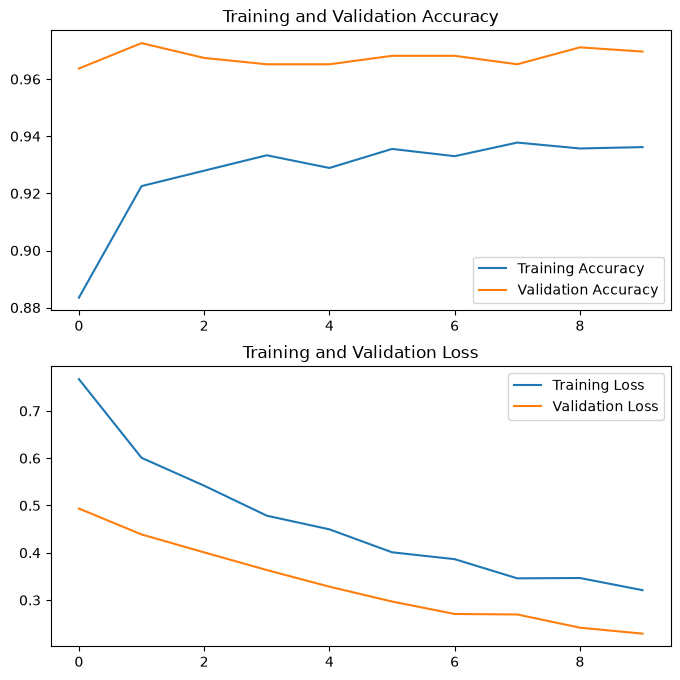

In [6]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS
)

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

## 5. Export Model to ONNX Format

In [7]:
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
from tf2onnx import tf_loader
from tf2onnx.tfonnx import process_tf_graph
from tf2onnx.optimizer import optimize_graph
from tf2onnx import utils
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

onnx_path = r'D:\MTEC\Image-Processing\Cat and Dog Classification\cat_dog_classifier.onnx'

# Define input signature
input_signature = [tf.TensorSpec((None, None, None, 3), tf.float32, name='image_input')]

@tf.function(input_signature=input_signature)
def model_fn(images):
    return model(images)

concrete_func = model_fn.get_concrete_function()
frozen_func = convert_variables_to_constants_v2(concrete_func)

input_names = [inp.name for inp in frozen_func.inputs]
output_names = [out.name for out in frozen_func.outputs]

with tf.Graph().as_default() as tf_graph:
    tf.import_graph_def(frozen_func.graph.as_graph_def(), name='')
    with tf_loader.tf_session(graph=tf_graph):
        g = process_tf_graph(tf_graph, input_names=input_names, output_names=output_names)
        onnx_graph = optimize_graph(g)
        model_proto = onnx_graph.make_model("cat_dog_classifier")
        utils.save_protobuf(onnx_path, model_proto)

print(f"Exported dynamic ONNX model successfully to '{onnx_path}'!")


Exported dynamic ONNX model successfully to 'D:\MTEC\Image-Processing\Cat and Dog Classification\cat_dog_classifier.onnx'!


## 6. Evaluate and Visualize Predictions

43/43 ━━━━━━━━━━━━━━━━━━━━ 37s 729ms/step - accuracy: 0.9770 - loss: 0.2143

🎯 Final Test Set Accuracy: 97.70%


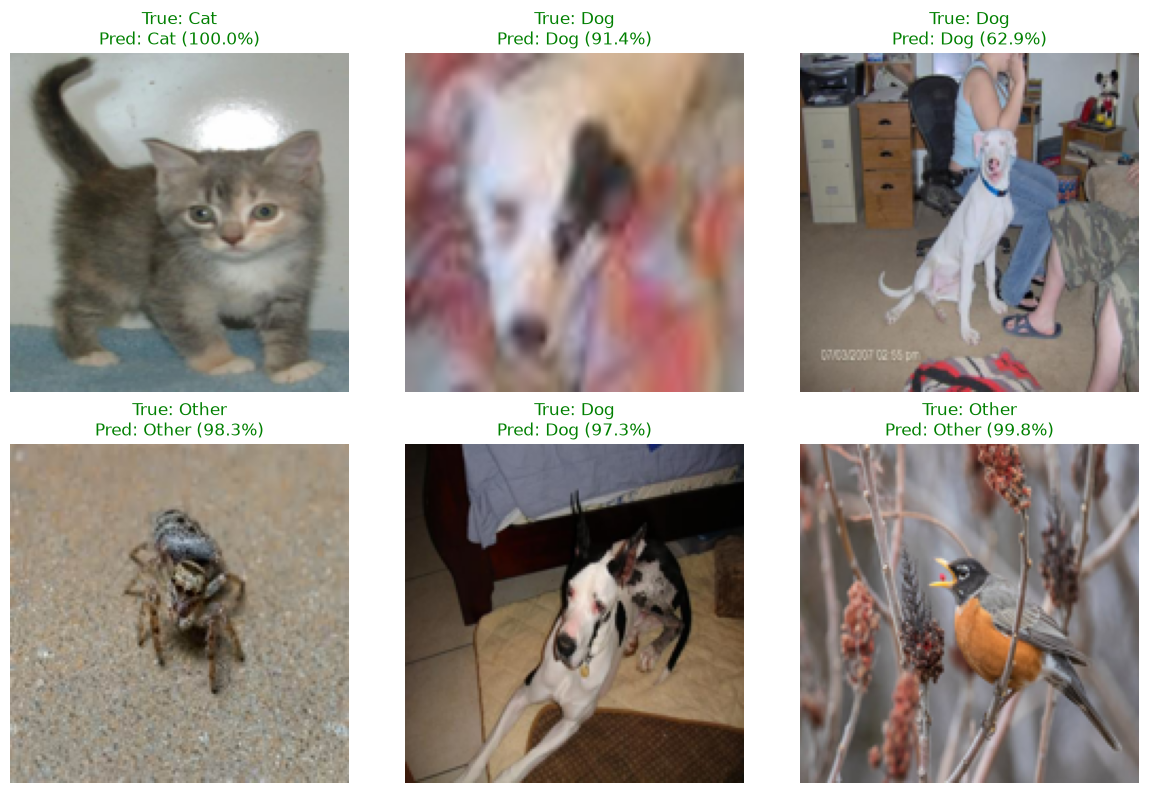

In [8]:
# 1. Evaluate accuracy on the unused test set
test_dataset = tf.data.Dataset.from_tensor_slices((test_images, test_labels)).batch(BATCH_SIZE)
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\n🎯 Final Test Set Accuracy: {test_acc * 100:.2f}%")

# 2. Visualize predictions on random test images
num_images_to_show = 6
plt.figure(figsize=(12, 8))

random_indices = np.random.choice(len(test_images), min(num_images_to_show, len(test_images)), replace=False)

for i, idx in enumerate(random_indices):
    img_array = test_images[idx]
    true_label_idx = test_labels[idx]
    true_label_name = class_names[true_label_idx]
    
    # Predict (Returns an array of 3 probabilities: [Cat, Dog, Other])
    prediction_input = tf.expand_dims(img_array, 0)
    scores = model.predict(prediction_input, verbose=0)[0]
    
    pred_label_idx = np.argmax(scores)
    pred_label_name = class_names[pred_label_idx]
    confidence = scores[pred_label_idx] * 100
        
    # Plot
    plt.subplot(2, 3, i + 1)
    plt.imshow(img_array.astype('uint8'))
    plt.axis('off')
    
    color = 'green' if pred_label_idx == true_label_idx else 'red'
    plt.title(f"True: {true_label_name}\nPred: {pred_label_name} ({confidence:.1f}%)", color=color)

plt.tight_layout()
plt.show()